<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter3/angled_strike.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Snap time, snap angle and maximum angle of oscillation vs angle.

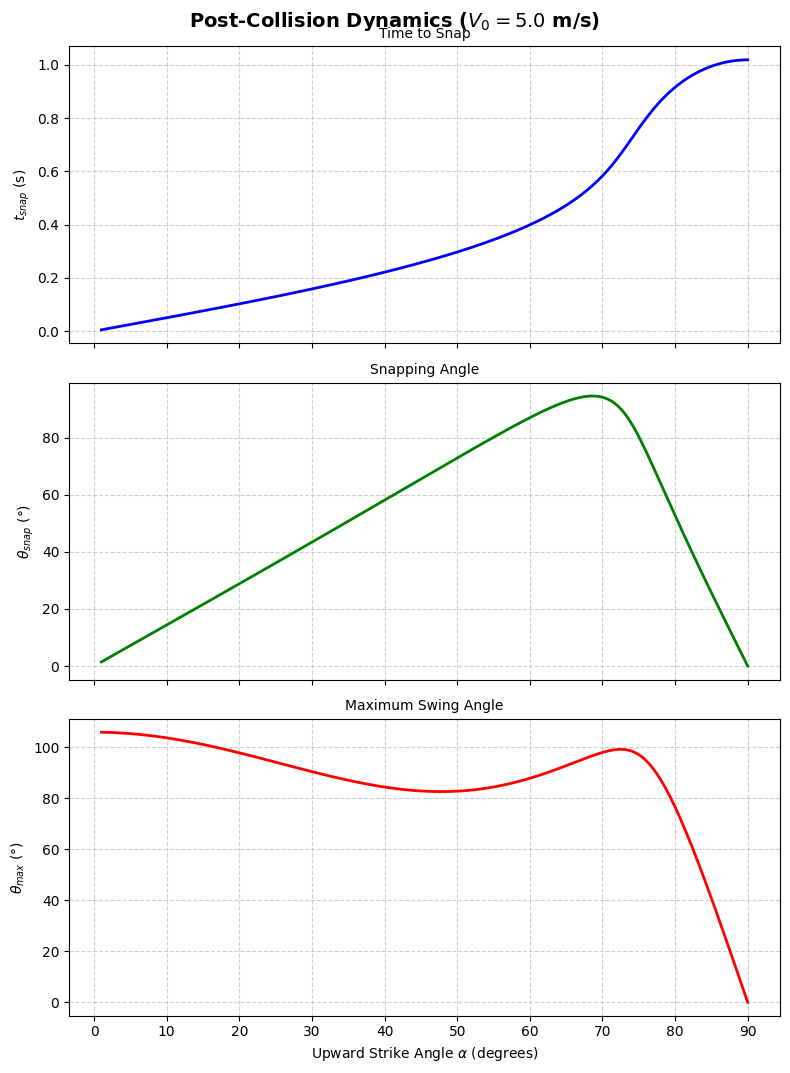

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. System Parameters
# ==========================================
g = 9.81        # Acceleration due to gravity (m/s^2)
l = 1.0         # Length of the pendulum string (m)
V0 = 5.0        # Initial launch speed (m/s)

# Array of upward hit angles alpha
alphas_deg = np.linspace(1, 90, 200)
alphas_rad = np.radians(alphas_deg)

t_snaps = []
theta_snaps = []
theta_maxs = []

# ==========================================
# 2. Calculate Dynamics
# ==========================================
for alpha in alphas_rad:
    coeffs = [
        0.25 * g**2,
        -V0 * g * np.sin(alpha),
        V0**2 + l * g,
        -2 * l * V0 * np.sin(alpha)
    ]

    roots = np.roots(coeffs)
    real_pos_roots = [np.real(r) for r in roots if np.isreal(r) and np.real(r) > 1e-5]

    if len(real_pos_roots) == 0:
        t_snaps.append(np.nan)
        theta_snaps.append(np.nan)
        theta_maxs.append(np.nan)
        continue

    t_s = min(real_pos_roots)
    t_snaps.append(t_s)

    x_s = V0 * np.cos(alpha) * t_s
    y_s = -l + V0 * np.sin(alpha) * t_s - 0.5 * g * t_s**2
    th_s = np.arctan2(x_s, -y_s)
    theta_snaps.append(np.degrees(th_s))

    v_t = V0 * np.cos(alpha) * np.cos(th_s) + (V0 * np.sin(alpha) - g * t_s) * np.sin(th_s)
    cos_th_max = np.cos(th_s) - (v_t**2) / (2 * g * l)

    if cos_th_max <= -1.0:
        theta_maxs.append(180.0)
    else:
        theta_maxs.append(np.degrees(np.arccos(cos_th_max)))

# ==========================================
# 3. Vertical Plotting
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 12), sharex=True)
fig.suptitle(f'Post-Collision Dynamics ($V_0 = {V0}$ m/s)', fontsize=14, weight='bold', y=0.92)

ax1.plot(alphas_deg, t_snaps, 'b-', linewidth=2)
ax1.set_ylabel('$t_{snap}$ (s)')
ax1.set_title('Time to Snap', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(alphas_deg, theta_snaps, 'g-', linewidth=2)
ax2.set_ylabel('$\\theta_{snap}$ (°)')
ax2.set_title('Snapping Angle', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)

ax3.plot(alphas_deg, theta_maxs, 'r-', linewidth=2)
ax3.set_ylabel('$\\theta_{max}$ (°)')
ax3.set_xlabel('Upward Strike Angle $\\alpha$ (degrees)')
ax3.set_title('Maximum Swing Angle', fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.6)

# Set x-ticks at intervals of 10
ax3.set_xticks(np.arange(0, 91, 10))

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()